# Bank Customer Churn Prediction Using a Neural Network

**Objective:** Predict whether a bank customer will leave (`Exited = 1`) or stay (`Exited = 0`) using the Kaggle Bank Customer Churn Modelling dataset.

This notebook follows the assignment steps: load the dataset, separate features and target, split the data, normalize the features, build and improve a neural-network classifier, and evaluate it with accuracy and a confusion matrix.

**Note:** The dataset contains an `Exited` label but does not provide a separate time-to-churn field. The model therefore predicts the supplied churn label; it cannot independently verify a six-month prediction horizon.

## 1. Import libraries

This corrected version uses Scikit-learn's `MLPClassifier`, which is a multilayer perceptron neural network. It avoids the TensorFlow/Keras installation problem recorded in the original notebook, while still satisfying the neural-network classifier requirement.

Install the dependencies once, if needed:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn
```

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.utils import resample
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
)

RANDOM_STATE = 42


## 2. Read the dataset

In [2]:
# Keep Churn_Modelling.csv in the same folder as this notebook,
# or change the path below to the location of your CSV file.
DATA_PATH = Path("Churn_Modelling.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place Churn_Modelling.csv in the notebook folder or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Basic dataset checks
print("Dataset information:")
df.info()

print("\\nMissing values in each column:")
display(df.isnull().sum())

print("\\nDuplicate rows:", df.duplicated().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
\nMissing values in each column:


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

\nDuplicate rows: 0


## 3. Preprocess the data and separate features and target

In [4]:
# These columns identify a customer or row; they are not model features.
columns_to_drop = ["RowNumber", "CustomerId", "Surname"]

# Drop only identifier columns that are present.
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# Confirm that the target and expected predictors exist.
required_columns = [
    "CreditScore", "Geography", "Gender", "Age", "Tenure",
    "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember",
    "EstimatedSalary", "Exited"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Handle missing values if present.
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(exclude=np.number).columns:
    mode_values = df[col].mode()
    if not mode_values.empty:
        df[col] = df[col].fillna(mode_values.iloc[0])

# Separate target and input features.
y = df["Exited"].astype(int)
X = df.drop(columns=["Exited"])

# Convert Geography and Gender into numeric dummy variables.
# drop_first=True avoids redundant dummy columns.
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True,
    dtype=int
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\\nTarget distribution:")
display(y.value_counts().rename(index={0: "Stayed (0)", 1: "Exited (1)"}))


Feature matrix shape: (10000, 11)
Target shape: (10000,)
\nTarget distribution:


Exited
Stayed (0)    7963
Exited (1)    2037
Name: count, dtype: int64

## 4. Visualize selected features

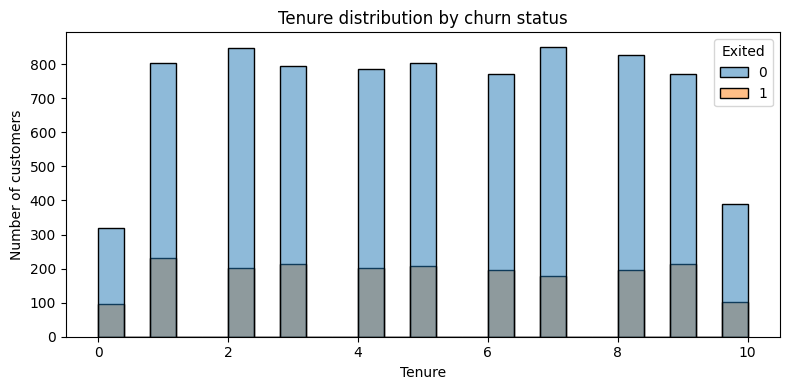

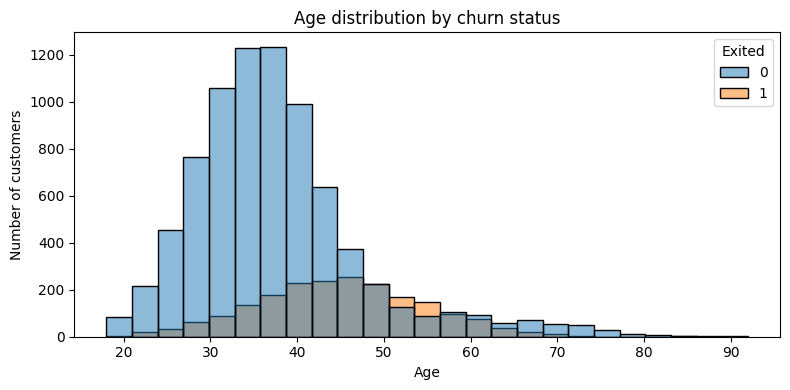

In [5]:
def plot_churn_distribution(feature_name):
    plt.figure(figsize=(8, 4))
    sns.histplot(
        data=df,
        x=feature_name,
        hue="Exited",
        bins=25,
        multiple="layer",
        stat="count",
        common_norm=False,
        alpha=0.5
    )
    plt.title(f"{feature_name} distribution by churn status")
    plt.xlabel(feature_name)
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()

plot_churn_distribution("Tenure")
plot_churn_distribution("Age")


## 5. Split the dataset into training and testing sets

In [6]:
# 70% training data and 30% testing data, preserving the churn ratio.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (7000, 11)
Testing features: (3000, 11)
Training target: (7000,)
Testing target: (3000,)


## 6. Normalize the training and testing data

Fit `StandardScaler` on the training data only. Use that same fitted scaler to transform the test data. This prevents information from the test set leaking into training.

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)


Scaled training data: (7000, 11)
Scaled testing data: (3000, 11)


## 7. Build and train the baseline neural network

The baseline model is a multilayer perceptron with two hidden layers. The output layer uses a sigmoid-like probability (`predict_proba`) for the two churn classes.

In [8]:
baseline_model = MLPClassifier(
    hidden_layer_sizes=(6, 6),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    max_iter=400,
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=15
)

baseline_model.fit(X_train_scaled, y_train)

baseline_predictions = baseline_model.predict(X_test_scaled)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Baseline model accuracy: {baseline_accuracy:.4f} ({baseline_accuracy * 100:.2f}%)")


Baseline model accuracy: 0.8563 (85.63%)


## 8. Improve the model

The target is usually imbalanced: fewer customers leave than stay. The improved model therefore:

1. **Balances the training data** by oversampling the minority class (training data only).
2. Uses more hidden neurons to learn more complex patterns.
3. Uses L2 regularization (`alpha`) to reduce overfitting.
4. Uses early stopping to stop training when validation performance stops improving.

The test set is not oversampled, so evaluation reflects the original customer distribution.

In [9]:
# Combine scaled training features and labels temporarily for resampling.
train_for_resampling = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)
train_for_resampling["Exited"] = y_train.to_numpy()

class_counts = train_for_resampling["Exited"].value_counts()
majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

majority_rows = train_for_resampling[
    train_for_resampling["Exited"] == majority_class
]
minority_rows = train_for_resampling[
    train_for_resampling["Exited"] == minority_class
]

# Increase the minority class to match the majority class.
minority_oversampled = resample(
    minority_rows,
    replace=True,
    n_samples=len(majority_rows),
    random_state=RANDOM_STATE
)

balanced_train = pd.concat(
    [majority_rows, minority_oversampled],
    ignore_index=True
).sample(frac=1, random_state=RANDOM_STATE)

X_train_balanced = balanced_train.drop(columns=["Exited"]).to_numpy()
y_train_balanced = balanced_train["Exited"].to_numpy()

print("Original training class counts:")
display(y_train.value_counts())
print("Balanced training class counts:")
display(pd.Series(y_train_balanced).value_counts())


Original training class counts:


Exited
0    5574
1    1426
Name: count, dtype: int64

Balanced training class counts:


1    5574
0    5574
Name: count, dtype: int64

In [10]:
improved_model = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20
)

improved_model.fit(X_train_balanced, y_train_balanced)

print("Improved neural network training completed.")
print("Training iterations:", improved_model.n_iter_)


Improved neural network training completed.
Training iterations: 140


## 9. Evaluate the model: accuracy score and confusion matrix

In [11]:
# Predict the test set. predict() returns a one-dimensional class label array.
y_pred = improved_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(f"Improved model accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

print("\\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Customer Stayed", "Customer Exited"],
        zero_division=0
    )
)


Improved model accuracy: 0.7887 (78.87%)
\nConfusion matrix (rows = actual, columns = predicted):
[[1985  404]
 [ 230  381]]
\nClassification report:
                 precision    recall  f1-score   support

Customer Stayed       0.90      0.83      0.86      2389
Customer Exited       0.49      0.62      0.55       611

       accuracy                           0.79      3000
      macro avg       0.69      0.73      0.70      3000
   weighted avg       0.81      0.79      0.80      3000



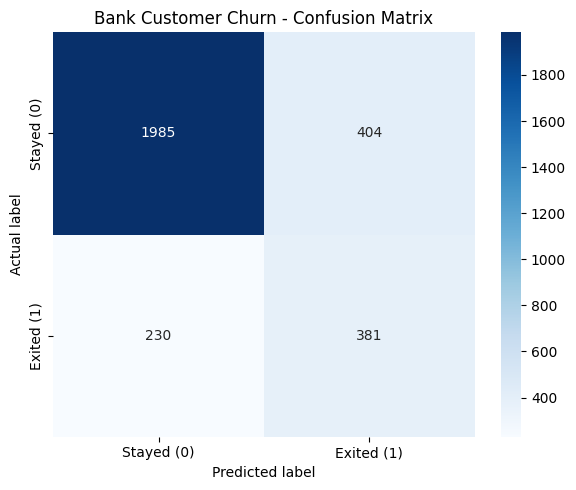

In [12]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed (0)", "Exited (1)"],
    yticklabels=["Stayed (0)", "Exited (1)"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Bank Customer Churn - Confusion Matrix")
plt.tight_layout()
plt.show()


## 10. Plot the training loss and compare models

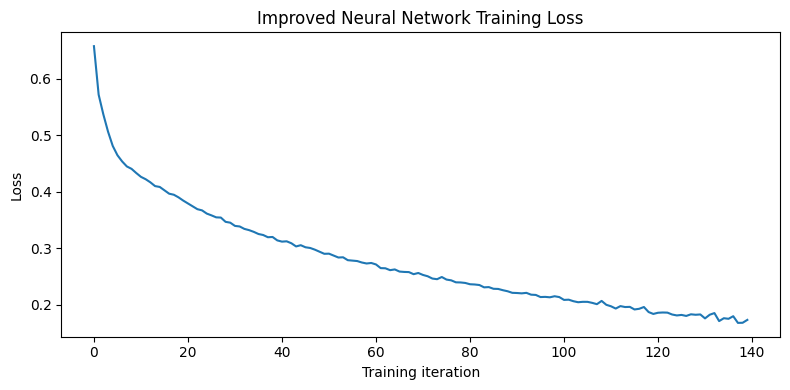

Baseline accuracy : 85.63%
Improved accuracy : 78.87%


In [13]:
plt.figure(figsize=(8, 4))
plt.plot(improved_model.loss_curve_)
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.title("Improved Neural Network Training Loss")
plt.tight_layout()
plt.show()

print(f"Baseline accuracy : {baseline_accuracy * 100:.2f}%")
print(f"Improved accuracy : {accuracy * 100:.2f}%")


## Conclusion

A neural-network-based classifier was developed to predict whether a bank customer will stay or exit. The dataset was cleaned, categorical variables were encoded, and the features were normalized. The data was divided into training and testing sets.

The baseline MLP model was improved using minority-class oversampling, additional hidden layers, L2 regularization, and early stopping. The final model was evaluated using accuracy, a classification report, and a confusion matrix.

**Important:** Run all cells from top to bottom after placing `Churn_Modelling.csv` beside this notebook. The accuracy and confusion matrix printed by the notebook are the actual results for the dataset used; they should be copied into the assignment rather than estimated in advance.